# Теория графовых сетей: рисунки к пояснению `docs/` (§ 2.7 диссертации)

Ноутбук воспроизводит три иллюстрации интерактивного пояснения https://d2718281828nis.github.io/ML-MachineLearning-Graphs/ в статическом виде:

1. **Спектр лапласиана** графа $k$ ближайших соседей на наборе «цепочки»: кратность нулевого собственного значения $\mathbf L=\mathbf D-\mathbf A$ равна числу компонент связности.
2. **Передача сообщений** на графе из `docs/assets/mp.js`: вершины-«близнецы» A и B с одинаковым признаком и разными соседями; GCN, GATv2 и сеть без рёбер.
3. **Лаборатория $\Delta_G$** из `docs/assets/lab.js`: одна и та же сеть с графом и без рёбер и отдельный перцептрон на гомофильных сообществах, на случайных рёбрах и на цепочках.

Параметры моделей перенесены из файлов `docs/assets/*.js`; генератор случайных чисел – NumPy, поэтому числа могут немного отличаться от страницы в браузере.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False, 'figure.dpi': 110})
OUT = Path('output/gnn_theory'); OUT.mkdir(parents=True, exist_ok=True)
RED, GREEN, GREY, ACC = '#d62728', '#2ca02c', '#7f7f7f', '#0B5563'

def knn_graph(P, k):
    # симметричный граф k ближайших соседей, как U.knnGraph в docs/assets/common.js
    d2 = ((P[:, None, :] - P[None, :, :]) ** 2).sum(-1); np.fill_diagonal(d2, np.inf)
    order = np.argsort(d2, axis=1)
    A = np.zeros((len(P), len(P)))
    for i in range(len(P)):
        A[i, order[i, :k]] = 1
    A = np.maximum(A, A.T)
    kdist = np.sqrt(np.take_along_axis(d2, order[:, :6], axis=1))
    return A, kdist

df = pd.read_csv('../datasets/df_red_green_chains.csv')
P = df[['X', 'Y']].to_numpy(float); y = (df['Color'] == 'red').astype(int).to_numpy()
print('точек', len(y), 'красных', y.sum())

точек 1672 красных 227


## 1. Спектр лапласиана и компоненты связности

$\mathbf x^{\top}\mathbf L\mathbf x=\sum_{(i,j)\in E}(x_i-x_j)^2$ равна нулю только на сигналах, постоянных на каждой компоненте, поэтому число нулевых собственных значений равно числу компонент связности.

 k  нулевых собственных значений  компонент связности  первое ненулевое
 1                           568                  568          0.152241
 2                           105                  105          0.006846
 3                            55                   55          0.002156
 4                            26                   26          0.000776
 5                            12                   12          0.000355
 6                             5                    5          0.000537
 7                             2                    2          0.000935
 8                             1                    1          0.002528
 9                             1                    1          0.003575
10                             1                    1          0.004874


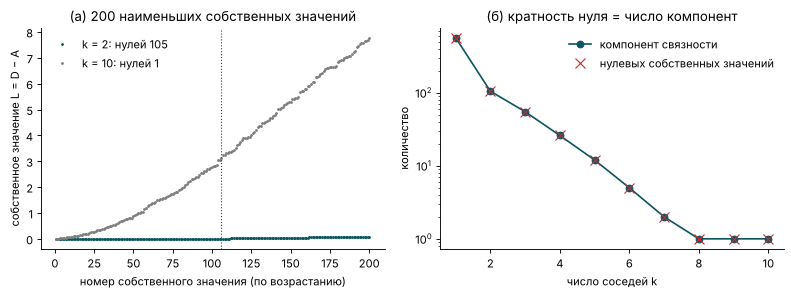

In [2]:
rows = []
spectra = {}
for k in range(1, 11):
    A, _ = knn_graph(P, k)
    L = np.diag(A.sum(1)) - A
    lam = np.linalg.eigvalsh(L)
    nzero = int((lam < 1e-8).sum())
    ncomp = connected_components(csr_matrix(A), directed=False)[0]
    rows.append((k, nzero, ncomp, lam[nzero] if nzero < len(lam) else np.nan))
    if k in (2, 10): spectra[k] = lam
tab = pd.DataFrame(rows, columns=['k', 'нулевых собственных значений', 'компонент связности', 'первое ненулевое'])
print(tab.to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
for k, c in ((2, ACC), (10, GREY)):
    lam = spectra[k]; ax[0].plot(np.arange(1, 201), lam[:200], '.', ms=3, color=c, label=f'k = {k}: нулей {int((lam < 1e-8).sum())}')
ax[0].axvline(int((spectra[2] < 1e-8).sum()) + 0.5, color=ACC, ls=':', lw=1)
ax[0].set_xlabel('номер собственного значения (по возрастанию)'); ax[0].set_ylabel('собственное значение L = D − A')
ax[0].set_title('(а) 200 наименьших собственных значений'); ax[0].legend(frameon=False)
ax[1].plot(tab['k'], tab['компонент связности'], 'o-', color=ACC, label='компонент связности')
ax[1].plot(tab['k'], tab['нулевых собственных значений'], 'x', color=RED, ms=9, label='нулевых собственных значений')
ax[1].set_yscale('log'); ax[1].set_xlabel('число соседей k'); ax[1].set_ylabel('количество')
ax[1].set_title('(б) кратность нуля = число компонент'); ax[1].legend(frameon=False)
fig.tight_layout(); fig.savefig(OUT / 'laplacian_spectrum_components.png', dpi=200, bbox_inches='tight'); plt.show()

## 2. Передача сообщений: вершины-«близнецы»

Граф, признаки и параметры – из `docs/assets/mp.js`: 10 вершин, A и B имеют одинаковый признак 0,3, у A соседи положительные, у B – отрицательные; три слоя $h_i'=\tanh\big(1{,}5\sum_j c_{ij}h_j\big)$ с весами GCN, GATv2 (фиксированные иллюстративные параметры) и при пустом графе.

gcn A: [0.3   0.826 0.842 0.869] B: [ 0.3   -0.708 -0.695 -0.785]
gat A: [0.3   0.703 0.801 0.832] B: [ 0.3    0.178 -0.076 -0.475]
none A: [0.3   0.422 0.56  0.686] B: [0.3   0.422 0.56  0.686]


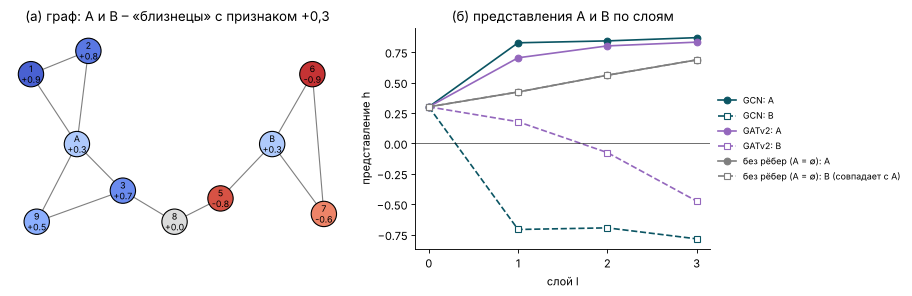

In [3]:
nodes = ['A', '1', '2', '3', 'B', '5', '6', '7', '8', '9']
xy = np.array([[150, 200], [70, 110], [170, 80], [230, 260], [490, 200], [400, 270], [560, 110], [580, 290], [320, 300], [80, 300]], float)
f0 = np.array([0.3, 0.9, 0.8, 0.7, 0.3, -0.8, -0.9, -0.6, 0.0, 0.5])
E = [(0, 1), (0, 2), (0, 3), (1, 2), (0, 9), (3, 8), (8, 5), (4, 5), (4, 6), (4, 7), (6, 7), (3, 9)]
LAYERS, WGT = 3, 1.5
GW = np.array([[1, -1], [-1, 1], [1, 1], [-1, -1]], float); GA = np.array([-2.5, -2.5, 0.8, 0.0])
lrelu = lambda z: np.where(z > 0, z, 0.2 * z)
def coeffs(h, adj, mode):
    n = len(h); C = np.zeros((n, n))
    for i in range(n):
        N = [i] + adj[i]
        if mode == 'gat':
            e = np.array([GA @ lrelu(GW @ np.array([h[i], h[j]])) for j in N]); ex = np.exp(e - e.max()); C[i, N] = ex / ex.sum()
        else:
            C[i, N] = [1 / np.sqrt((len(adj[i]) + 1) * (len(adj[j]) + 1)) for j in N]
    return C
def forward(mode):
    adj = [[] for _ in nodes]
    if mode != 'none':
        for u, v in E: adj[u].append(v); adj[v].append(u)
    H = [f0.copy()]
    for _ in range(LAYERS): H.append(np.tanh(WGT * coeffs(H[-1], adj, mode) @ H[-1]))
    return np.array(H)
res = {m: forward(m) for m in ('gcn', 'gat', 'none')}
for m, H in res.items(): print(m, 'A:', np.round(H[:, 0], 3), 'B:', np.round(H[:, 4], 3))

fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.8), gridspec_kw={'width_ratios': [1.15, 1]})
for u, v in E: ax[0].plot(*xy[[u, v]].T, color=GREY, lw=1, zorder=1)
sc = ax[0].scatter(*xy.T, c=f0, cmap='coolwarm_r', vmin=-1, vmax=1, s=520, edgecolor='k', zorder=2)
for i, nm in enumerate(nodes): ax[0].text(*xy[i], f'{nm}\n{f0[i]:+.1f}', ha='center', va='center', fontsize=8, zorder=3)
ax[0].set_xlim(30, 620); ax[0].set_ylim(335, 50); ax[0].axis('off'); ax[0].set_title('(а) граф: A и B – «близнецы» с признаком +0,3')
lab = {'gcn': 'GCN', 'gat': 'GATv2', 'none': 'без рёбер (A = ∅)'}; col = {'gcn': ACC, 'gat': '#9467bd', 'none': GREY}
for m, H in res.items():
    ax[1].plot(range(LAYERS + 1), H[:, 0], '-o', color=col[m], label=f'{lab[m]}: A')
    ax[1].plot(range(LAYERS + 1), H[:, 4], '--s', color=col[m], label=f'{lab[m]}: B' + (' (совпадает с A)' if m == 'none' else ''), mfc='white')
ax[1].axhline(0, color='k', lw=0.5); ax[1].set_xticks(range(LAYERS + 1)); ax[1].set_xlabel('слой l'); ax[1].set_ylabel('представление h')
ax[1].set_title('(б) представления A и B по слоям'); ax[1].legend(frameon=False, fontsize=8, ncol=1, loc='center left', bbox_to_anchor=(1.0, 0.5))
fig.tight_layout(); fig.savefig(OUT / 'message_passing_twins.png', dpi=200, bbox_inches='tight'); plt.show()

## 3. Лаборатория $\Delta_G$: та же сеть с графом и без рёбер

Как в `docs/assets/lab.js`: признаки сглаживаются $K$ шагами $\hat{\mathbf A}=\tilde{\mathbf D}^{-1/2}\tilde{\mathbf A}\tilde{\mathbf D}^{-1/2}$ (упрощённая графовая свёртка), затем одна и та же голова – перцептрон с одним скрытым слоем (16, tanh, Adam, 160 эпох, взвешенная по классам кросс-энтропия); контроль $\mathbf A=\varnothing$ – та же голова на исходных признаках с теми же фолдами и начальными значениями; отдельный перцептрон – свои гиперпараметры (32 нейрона, 260 эпох). Метрика – F1 красного класса, 5 стратифицированных фолдов.

In [4]:
def rng(seed): return np.random.default_rng(seed)
def make_sbm(random_edges, seed=7):
    R = rng(seed); n = 360; y = np.array([1 if i < 90 else 0 for i in range(n)])
    grp = np.array([(i % 2) if y[i] else 2 + (i % 5) for i in range(n)])
    X = np.c_[R.normal(size=n) + np.where(y == 1, 0.45, -0.15), R.normal(size=n) + np.where(y == 1, 0.3, 0.0)]
    pr = np.where(grp[:, None] == grp[None, :], 0.11, 0.0025)
    U = R.random((n, n)); A = np.triu(U < pr, 1).astype(float); A = A + A.T
    if random_edges:
        m = int(A.sum() / 2); A = np.zeros((n, n)); e = 0
        while e < m:
            a, b = R.integers(n), R.integers(n)
            if a != b and not A[a, b]: A[a, b] = A[b, a] = 1; e += 1
    return X, A, y
def make_chains(k=2):
    A, kd = knn_graph(P, k)
    X = np.c_[np.log(kd[:, 1]), np.log(kd[:, 4])]
    return X, A, y
def propagate(A, X, K):
    At = A + np.eye(len(A)); d = At.sum(1); Ah = At / np.sqrt(d[:, None] * d[None, :])
    for _ in range(K): X = Ah @ X
    return X
def folds(y, k=5, seed=11):
    R = rng(seed); pos = np.flatnonzero(y == 1); neg = np.flatnonzero(y == 0); R.shuffle(pos); R.shuffle(neg)
    F = [[] for _ in range(k)]
    for t, i in enumerate(pos): F[t % k].append(i)
    for t, i in enumerate(neg): F[t % k].append(i)
    return [np.array(f) for f in F]
def train_mlp(X, y, tr, hidden=16, lr=0.03, epochs=160, seed=1, l2=1e-4):
    R = rng(seed); d = X.shape[1]
    W1 = R.normal(size=(hidden, d)) * np.sqrt(2 / d); b1 = np.zeros(hidden); W2 = R.normal(size=hidden) * np.sqrt(1 / hidden); b2 = 0.0
    pos = y[tr].sum(); neg = len(tr) - pos; w = np.where(y[tr] == 1, len(tr) / (2 * max(pos, 1)), len(tr) / (2 * max(neg, 1)))
    params = [W1, b1, W2]; M = [np.zeros_like(p) for p in params]; V = [np.zeros_like(p) for p in params]; mb = vb = 0.0
    Xt, yt = X[tr], y[tr]
    for ep in range(1, epochs + 1):
        H = np.tanh(Xt @ W1.T + b1); z = H @ W2 + b2; p = 1 / (1 + np.exp(-z)); g = w * (p - yt) / len(tr)
        gb2 = g.sum(); gW2 = H.T @ g; gH = np.outer(g, W2) * (1 - H ** 2); gb1 = gH.sum(0); gW1 = gH.T @ Xt
        for t, (pp, gg) in enumerate(zip(params, [gW1, gb1, gW2])):
            gg = gg + l2 * pp; M[t] = 0.9 * M[t] + 0.1 * gg; V[t] = 0.999 * V[t] + 0.001 * gg ** 2
            pp -= lr * (M[t] / (1 - 0.9 ** ep)) / (np.sqrt(V[t] / (1 - 0.999 ** ep)) + 1e-8)
        mb = 0.9 * mb + 0.1 * gb2; vb = 0.999 * vb + 0.001 * gb2 ** 2; b2 -= lr * (mb / (1 - 0.9 ** ep)) / (np.sqrt(vb / (1 - 0.999 ** ep)) + 1e-8)
    return lambda Z: 1 / (1 + np.exp(-(np.tanh(Z @ W1.T + b1) @ W2 + b2)))
def f1(y, yh):
    tp = ((yh == 1) & (y == 1)).sum(); fp = ((yh == 1) & (y == 0)).sum(); fn = ((yh == 0) & (y == 1)).sum()
    p = tp / (tp + fp) if tp + fp else 0; r = tp / (tp + fn) if tp + fn else 0
    return 2 * p * r / (p + r) if p + r else 0.0
def std(X, tr):
    mu = X[tr].mean(0); sd = X[tr].std(0); sd[sd == 0] = 1; return (X - mu) / sd
def evaluate(X, A, y, K, with_mlp=True):
    Xg = propagate(A, X, K); out = {'g': [], 'e': [], 'm': []}; F = folds(y)
    for f, te in enumerate(F):
        tr = np.concatenate([F[t] for t in range(len(F)) if t != f])
        zg, ze = std(Xg, tr), std(X, tr)
        mg = train_mlp(zg, y, tr, seed=100 + f); me = train_mlp(ze, y, tr, seed=100 + f)
        out['g'].append(f1(y[te], (mg(zg[te]) > 0.5).astype(int))); out['e'].append(f1(y[te], (me(ze[te]) > 0.5).astype(int)))
        if with_mlp:
            mm = train_mlp(ze, y, tr, hidden=32, lr=0.01, epochs=260, seed=900 + f, l2=1e-3)
            out['m'].append(f1(y[te], (mm(ze[te]) > 0.5).astype(int)))
    return {k: np.array(v) for k, v in out.items()}

def homophily1(A, y):
    r = A[y == 1]; return r[:, y == 1].sum() / r.sum()
DS = {'гомофильные сообщества': make_sbm(False), 'случайные рёбра': make_sbm(True), 'цепочки, k = 2': make_chains(2)}
results = {}
for name, (X, A, yy) in DS.items():
    r = evaluate(X, A, yy, K=2); results[name] = r
    d = r['g'] - r['e']
    print(f"{name}: h1 = {homophily1(A, yy):.2f}, доля красных {yy.mean():.3f}; F1 ГНС {r['g'].mean():.3f}, без рёбер {r['e'].mean():.3f}, МП {r['m'].mean():.3f}; ΔG = {d.mean():+.3f} (по фолдам {np.round(d, 2)})")

Xc, Ac, yc = DS['цепочки, k = 2']
Ks = [0, 1, 2, 4, 8, 12, 16, 20, 24, 32]
sweep = [(K, evaluate(Xc, Ac, yc, K, with_mlp=False)) for K in Ks]
ncomp, lab_c = connected_components(csr_matrix(Ac), directed=False)
size = np.bincount(lab_c)[lab_c]; tie = rng(99).permutation(len(yc)); order = np.lexsort((tie, -size))
flag = np.zeros(len(yc), int); flag[order[:yc.sum()]] = 1
comp_f1 = f1(yc, flag)
for K, r in sweep: print(f'K = {K:2d}: ГНС {r["g"].mean():.3f}, без рёбер {r["e"].mean():.3f}')
print('компонент', ncomp, 'F1 по размеру компоненты', round(comp_f1, 3))

гомофильные сообщества: h1 = 0.88, доля красных 0.250; F1 ГНС 0.799, без рёбер 0.353, МП 0.401; ΔG = +0.445 (по фолдам [0.51 0.36 0.46 0.3  0.6 ])
случайные рёбра: h1 = 0.20, доля красных 0.250; F1 ГНС 0.402, без рёбер 0.353, МП 0.401; ΔG = +0.049 (по фолдам [-0.04 -0.02 -0.01  0.04  0.27])
цепочки, k = 2: h1 = 1.00, доля красных 0.136; F1 ГНС 0.350, без рёбер 0.275, МП 0.271; ΔG = +0.075 (по фолдам [0.08 0.08 0.09 0.03 0.08])
K =  0: ГНС 0.275, без рёбер 0.275
K =  1: ГНС 0.339, без рёбер 0.275
K =  2: ГНС 0.350, без рёбер 0.275
K =  4: ГНС 0.317, без рёбер 0.275
K =  8: ГНС 0.327, без рёбер 0.275
K = 12: ГНС 0.376, без рёбер 0.275
K = 16: ГНС 0.418, без рёбер 0.275
K = 20: ГНС 0.453, без рёбер 0.275
K = 24: ГНС 0.472, без рёбер 0.275
K = 32: ГНС 0.494, без рёбер 0.275
компонент 105 F1 по размеру компоненты 1.0


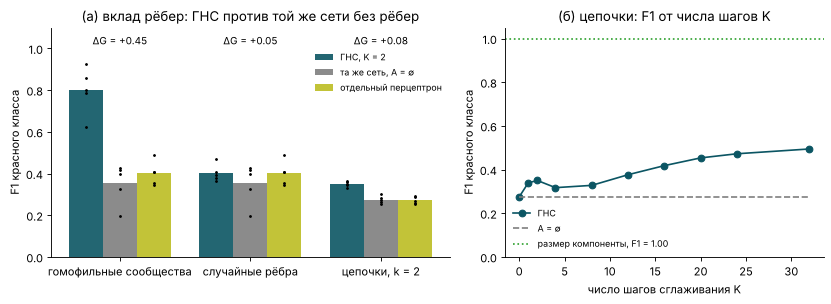

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.9), gridspec_kw={'width_ratios': [1.25, 1]})
names = list(results); x = np.arange(len(names)); wdt = 0.26
for j, (key, lbl, c) in enumerate((('g', 'ГНС, K = 2', ACC), ('e', 'та же сеть, A = ∅', GREY), ('m', 'отдельный перцептрон', '#bcbd22'))):
    vals = [results[n][key] for n in names]
    ax[0].bar(x + (j - 1) * wdt, [v.mean() for v in vals], wdt, color=c, label=lbl, alpha=0.9)
    for i, v in enumerate(vals): ax[0].plot(np.full(len(v), x[i] + (j - 1) * wdt), v, 'k.', ms=3)
for i, n in enumerate(names):
    d = results[n]['g'] - results[n]['e']
    ax[0].text(x[i], 1.02, f'ΔG = {d.mean():+.2f}', ha='center', fontsize=9)
ax[0].set_xticks(x); ax[0].set_xticklabels(names); ax[0].set_ylim(0, 1.1); ax[0].set_ylabel('F1 красного класса')
ax[0].set_title('(а) вклад рёбер: ГНС против той же сети без рёбер'); ax[0].legend(frameon=False, fontsize=8, loc='upper right', bbox_to_anchor=(1, 0.93))
ax[1].plot([k for k, _ in sweep], [r['g'].mean() for _, r in sweep], '-o', color=ACC, label='ГНС')
ax[1].plot([k for k, _ in sweep], [r['e'].mean() for _, r in sweep], '--', color=GREY, label='A = ∅')
ax[1].axhline(comp_f1, color=GREEN, ls=':', label=f'размер компоненты, F1 = {comp_f1:.2f}')
ax[1].set_xlabel('число шагов сглаживания K'); ax[1].set_ylabel('F1 красного класса'); ax[1].set_ylim(0, 1.05)
ax[1].set_title('(б) цепочки: F1 от числа шагов K'); ax[1].legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(OUT / 'edge_contribution_lab.png', dpi=200, bbox_inches='tight'); plt.show()